# Experiment 4: Why a Linear Neuron Cannot Learn XOR

## Objective

The goal of this experiment is to understand why a single linear neuron cannot perfectly learn the XOR problem.

A linear neuron computes:

\[
z = w_1x_1 + w_2x_2 + b
\]

We will:

1. create the XOR dataset;
2. build a single linear neuron;
3. train the neuron using PyTorch;
4. examine its predictions and loss;
5. understand why the model fails;
6. compare it later with a polynomial neuron.

This experiment provides motivation for using Polynomial Neural Networks (PNNs).

In [1]:
# Import important libraries
import torch
import torch.nn as nn
import torch.optim as optim

In [2]:
#Create XOR Data

X = torch.tensor([
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0]
])

y = torch.tensor([
    [0.0],
    [1.0],
    [1.0],
    [0.0]
])

print("Inputs:")
print(X)

print("\nTargets:")
print(y)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Inputs:
tensor([[0., 0.],
        [0., 1.],
        [1., 0.],
        [1., 1.]])

Targets:
tensor([[0.],
        [1.],
        [1.],
        [0.]])

X shape: torch.Size([4, 2])
y shape: torch.Size([4, 1])


In [4]:
# Build the model and print initial weights and bias
model = nn.Linear(2, 1)

print(model)

print("\nInitial weights:")
print(model.weight.data)

print("\nInitial bias:")
print(model.bias.data)

Linear(in_features=2, out_features=1, bias=True)

Initial weights:
tensor([[ 0.5949, -0.3812]])

Initial bias:
tensor([0.2441])


In [5]:
# Verify math using pytorch
# Verifying hand calculations/ raw outpus
# Raw outputs are called as logits

with torch.no_grad(): # We don't want to store gradient at this point to avoid learning, so we used no_grad()
    logits = model(X)
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= 0.5).float()

print("Raw outputs (logits):")
print(logits)

print("\nProbabilities:")
print(probabilities)

print("\nPredicted classes:")
print(predictions)

print("\nCorrect classes:")
print(y)

Raw outputs (logits):
tensor([[ 0.2441],
        [-0.1371],
        [ 0.8390],
        [ 0.4578]])

Probabilities:
tensor([[0.5607],
        [0.4658],
        [0.6982],
        [0.6125]])

Predicted classes:
tensor([[1.],
        [0.],
        [1.],
        [1.]])

Correct classes:
tensor([[0.],
        [1.],
        [1.],
        [0.]])


Logits that we got are not probabilities,  we would prefer output something like:
 0<= p <= 1, so that we can interprete as probability of class 1.
 Hence we use below sigmoid function.
 The sigmoid function is:

$$ \sigma(z)=\frac{1}{1+e^{-z}} $$

It converts any number:

$$ -\infty < z < +\infty $$

into:

$$ 0 < \sigma(z) < 1. $$

For example:

$$ z=-10 \Rightarrow \sigma(z)\approx0 $$ $$ z=0 \Rightarrow \sigma(z)=0.5 $$
z=10⇒σ(z)≈1.

In [6]:
# Calculating Loss using a Loss function to measure how bad the model perdicted

criterion = nn.BCEWithLogitsLoss() # For binary classification we use BCE...

logits = model(X)

loss = criterion(logits, y)

print("Initial loss:", loss.item())

Initial loss: 0.7234635353088379


##### Here we complete 1st half of the training process, but nothing has learned yet.

          INPUT
            X
            ↓
       model(X)
            ↓
         LOGITS
            ↓
BCEWithLogitsLoss(logits, y)
            ↓
          LOSS


##### Forward pass

X→prediction→loss

In [7]:
# Calculate BCE manually for each example to cross validate
manual_losses = -(
    y * torch.log(probabilities)
    +
    (1 - y) * torch.log(1 - probabilities)
)

print("\nLoss for each example:")
print(manual_losses)

print("\nAverage manual loss:")
print(manual_losses.mean())

print("\nPyTorch BCEWithLogitsLoss:")
print(criterion(logits, y))


Loss for each example:
tensor([[0.8226],
        [0.7641],
        [0.3592],
        [0.9480]])

Average manual loss:
tensor(0.7235)

PyTorch BCEWithLogitsLoss:
tensor(0.7235, grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)


In [8]:
# Checking gradients  
loss.backward()

print("Weights:")
print(model.weight.data)

print("\nWeight gradients:")
print(model.weight.grad)

print("\nBias:")
print(model.bias.data)

print("\nBias gradient:")
print(model.bias.grad)

Weights:
tensor([[ 0.5949, -0.3812]])

Weight gradients:
tensor([[0.0777, 0.0196]])

Bias:
tensor([0.2441])

Bias gradient:
tensor([0.0843])


## Training the Linear Neuron

We now train the linear neuron using gradient descent.

Each training iteration performs four main steps:

1. Forward pass — calculate the model output.
2. Calculate the loss.
3. Backpropagation — calculate gradients.
4. Update the model parameters.

The purpose of this experiment is to determine whether a single linear neuron can learn XOR.

In [10]:
#import torch
#import torch.nn as nn
#import torch.optim as optim

# Make the experiment reproducible
torch.manual_seed(42)

# Create a fresh linear neuron
model = nn.Linear(2, 1)

# Define the loss function
criterion = nn.BCEWithLogitsLoss()

# Define the optimizer
optimizer = optim.SGD(model.parameters(), lr=0.1)

print("Model:", model)
print("Optimizer:", optimizer)

Model: Linear(in_features=2, out_features=1, bias=True)
Optimizer: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.1
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


In [13]:
# The training loop

num_epochs = 1000

loss_history = []

for epoch in range(num_epochs):

    # 1. Clear gradients from the previous iteration
    optimizer.zero_grad()

    # 2. Forward pass
    logits = model(X)

    # 3. Calculate loss
    loss = criterion(logits, y)

    # 4. Calculate gradients
    loss.backward()

    # 5. Update parameters (weights and bias)
    optimizer.step()

    #6. Store loss for later analysis
    loss_history.append(loss.item())

    # Print progress every 100 epochs
    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch + 1:4d} | "
            f"Loss: {loss.item():.4f}"
        )

Epoch  100 | Loss: 0.6978
Epoch  200 | Loss: 0.6953
Epoch  300 | Loss: 0.6941
Epoch  400 | Loss: 0.6936
Epoch  500 | Loss: 0.6934
Epoch  600 | Loss: 0.6932
Epoch  700 | Loss: 0.6932
Epoch  800 | Loss: 0.6932
Epoch  900 | Loss: 0.6932
Epoch 1000 | Loss: 0.6932


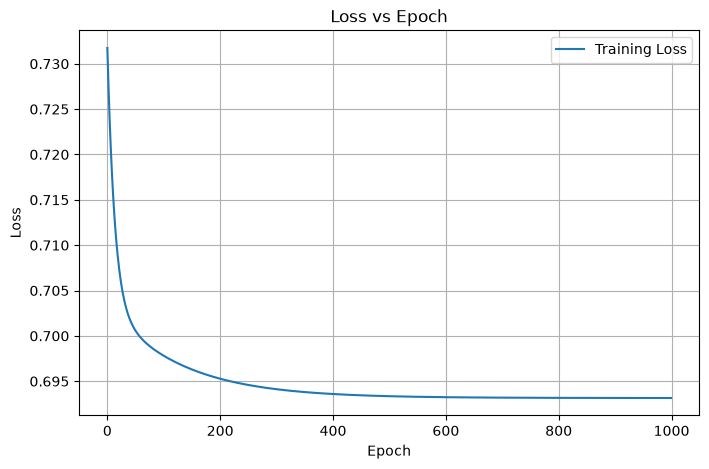

In [14]:
# Plot Loss Vs Epoch

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(loss_history, label="Training Loss")

plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

plt.show()

In [11]:
# Test the trained model

with torch.no_grad():

    logits = model(X)

    probabilities = torch.sigmoid(logits)

    predictions = (probabilities >= 0.5).float()


print("Final logits:")
print(logits)

print("\nFinal probabilities:")
print(probabilities)

print("\nPredictions:")
print(predictions)

print("\nTargets:")
print(y)

print("\nFinal weights:")
print(model.weight.data)

print("\nFinal bias:")
print(model.bias.data)

Final logits:
tensor([[-0.1657],
        [ 0.4212],
        [ 0.3750],
        [ 0.9619]])

Final probabilities:
tensor([[0.4587],
        [0.6038],
        [0.5927],
        [0.7235]])

Predictions:
tensor([[0.],
        [1.],
        [1.],
        [1.]])

Targets:
tensor([[0.],
        [1.],
        [1.],
        [0.]])

Final weights:
tensor([[0.5406, 0.5869]])

Final bias:
tensor([-0.1657])



## Experiment Conclusion

A single linear neuron was trained on the XOR dataset using PyTorch.

After 1000 training epochs, the model correctly classified three of the four examples, achieving 75% accuracy.

The model incorrectly classified (1,1) because XOR is not linearly separable. A single linear neuron cannot represent the required decision boundary.

This experiment demonstrates a representational limitation of linear models and motivates introducing polynomial interaction features such as x1*x2.

**Next experiment:** Solve XOR using a degree-2 polynomial neuron.